In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model

In [ ]:
# Set dataset path and select categories

In [7]:
DATASET_PATH = r"C:\Users\Dell\Downloads\caltech-101\caltech-101\101_ObjectCategories\101_ObjectCategories"

categories = [
    "cougar_body",
    "yin_yang",
    "windsor_chair",
    "wrench",
    "wheelchair"
]

IMG_SIZE = 224

In [ ]:
# Load and preprocess images

In [8]:
images = []
labels = []

for label, category in enumerate(categories):

    folder = Path(DATASET_PATH) / category

    image_files = list(folder.glob("*.jpg"))[:100]

    for file in image_files:

        img = tf.keras.utils.load_img(
            file,
            target_size=(224, 224)
        )

        img = tf.keras.utils.img_to_array(img)

        images.append(img)
        labels.append(label)

X = np.array(images, dtype=np.float32)
y = np.array(labels)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Total images:", len(X))

Images shape: (261, 224, 224, 3)
Labels shape: (261,)
Total images: 261


In [ ]:
# Split training and testing data

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 208
Testing images: 53


In [ ]:
# Preprocess images for VGG16

In [11]:
X_train = preprocess_input(X_train)
X_test = preprocess_input(X_test)

In [ ]:
# Load pretrained VGG16 model

In [12]:
base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 148s 3us/step


In [ ]:
# Extract features using GlobalAveragePooling2D

In [14]:
feature_extractor = Model(
    inputs=base_model.input,
    outputs=GlobalAveragePooling2D()(base_model.output)
)

train_features = feature_extractor.predict(
    X_train,
    batch_size=16
)

test_features = feature_extractor.predict(
    X_test,
    batch_size=16
)

print("Training features:", train_features.shape)
print("Testing features:", test_features.shape)

13/13 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step
Training features: (208, 512)
Testing features: (53, 512)


In [ ]:
# Create custom classification layer

In [15]:
model = tf.keras.Sequential([
    Dense(5, activation="softmax", input_shape=(512,))
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 5)                   │           2,565 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,565 (10.02 KB)

 Trainable params: 2,565 (10.02 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the classifier

In [16]:
history = model.fit(
    train_features,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 202ms/step - accuracy: 0.3494 - loss: 4.7753 - val_accuracy: 0.3810 - val_loss: 3.5866
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.6506 - loss: 1.9180 - val_accuracy: 0.5476 - val_loss: 2.9142
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.7651 - loss: 1.3379 - val_accuracy: 0.5952 - val_loss: 2.2627
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8434 - loss: 0.7785 - val_accuracy: 0.6190 - val_loss: 1.5864
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8976 - loss: 0.3961 - val_accuracy: 0.6905 - val_loss: 1.2829
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9337 - loss: 0.2128 - val_accuracy: 0.7143 - val_loss: 1.1624
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9639 - loss: 0.1584 - val_accuracy: 0.7619 - val_loss: 1.0330
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9759 - loss: 0.1170 - val_accuracy: 0.7619 - val_loss: 0.8861

In [ ]:
# Evaluate testing accuracy

In [17]:
loss, accuracy = model.evaluate(test_features, y_test)

print("Testing Accuracy:", accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8868 - loss: 0.3648
Testing Accuracy: 88.67924809455872 %


In [ ]:
# Display accuracy graph

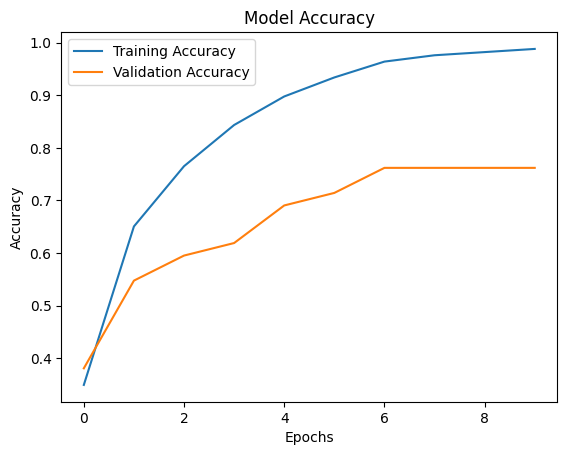

In [18]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")

plt.legend()
plt.show()

Here are **25 important code-based viva questions with answers** for **Practical 26 – Object Classification using VGG16 as a Feature Extractor with Caltech-101**.

I've focused on questions an external examiner can ask by pointing to specific lines of your code.

# VGG16 Feature Extraction – 25 Viva Questions

### 1. Dataset Loading and Preprocessing

**Q1. Why do we use `Path(DATASET_PATH)`?**  
Ans: To create a path object that helps access folders and files easily.

**Q2. What is the purpose of `enumerate(categories)`?**  
Ans: It assigns a numerical label to each category.

**Q3. Why do we use `folder.rglob("*")`?**  
Ans: To search for files inside a folder and its subfolders.

**Q4. Why do we use `file.suffix.lower()`?**  
Ans: To get the file extension in lowercase so we can identify image formats consistently.

**Q5. Why do we use `[:100]`?**  
Ans: To select a maximum of 100 images from each category.

**Q6. What does `target_size=(224,224)` do?**  
Ans: It resizes every image to 224 × 224 pixels because VGG16 expects this input size in our implementation.

**Q7. What does `img_to_array()` do?**  
Ans: It converts an image into a numerical array.

**Q8. Why do we convert images into NumPy arrays?**  
Ans: Because TensorFlow models accept numerical arrays as input.

**Q9. What does `train_test_split()` do?**  
Ans: It divides the dataset into training and testing sets.

**Q10. What is the purpose of `test_size=0.2`?**  
Ans: It reserves 20% of the data for testing and uses 80% for training.

### 2. VGG16 Model

**Q11. What is VGG16?**  
Ans: VGG16 is a pretrained Convolutional Neural Network developed by Oxford's Visual Geometry Group.

**Q12. What does `weights="imagenet"` mean?**  
Ans: It loads weights learned by VGG16 from the ImageNet dataset.

**Q13. What is the purpose of `include_top=False`?**  
Ans: It removes the original fully connected classification layers of VGG16.

**Q14. Why do we use `input_shape=(224,224,3)`?**  
Ans: It specifies the input image dimensions: height 224, width 224 and 3 RGB channels.

**Q15. What does `base_model.trainable=False` do?**  
Ans: It freezes the pretrained VGG16 layers so their weights are not updated during training.

**Q16. What is `preprocess_input()`?**  
Ans: It preprocesses images according to the input requirements of pretrained VGG16.

**Q17. Why do we use VGG16 as a feature extractor?**  
Ans: It extracts useful image features using its pretrained convolutional layers, saving training time.

### 3. Feature Extraction and Classification

**Q18. What is the purpose of `GlobalAveragePooling2D()`?**  
Ans: It converts feature maps into a one-dimensional feature vector by calculating the average of each feature map.

**Q19. Why do we use `Model(inputs=..., outputs=...)`?**  
Ans: To create a feature extraction model using the pretrained VGG16 network.

**Q20. What does `feature_extractor.predict()` do?**  
Ans: It extracts features from the training and testing images.

**Q21. Why do we use a Dense layer?**  
Ans: To classify the extracted features into different object categories.

**Q22. What is the purpose of `activation="softmax"`?**  
Ans: It converts the output values into probabilities for the five classes.

**Q23. Why do we use `sparse_categorical_crossentropy`?**  
Ans: It calculates classification loss when class labels are provided as integer values.

### 4. Model Training and Evaluation

**Q24. What does `model.fit()` do?**  
Ans: It trains the classification model using extracted training features and their labels.

**Q25. What does `model.evaluate()` return?**  
Ans: It returns the testing loss and testing accuracy.

---

## Important code lines to remember for your practical

| Code | Purpose |
|---|---|
| `VGG16(weights="imagenet")` | Load pretrained VGG16 |
| `include_top=False` | Remove original classifier |
| `base_model.trainable=False` | Freeze VGG16 |
| `preprocess_input()` | Preprocess images |
| `GlobalAveragePooling2D()` | Reduce feature maps |
| `feature_extractor.predict()` | Extract features |
| `Dense(5, activation="softmax")` | Classify five categories |
| `model.compile()` | Configure training |
| `model.fit()` | Train classifier |
| `model.evaluate()` | Test classifier |

**One important viva question:**

**Q. What is the difference between feature extraction and transfer learning?**

Ans:
- **Feature extraction:** Uses a pretrained model to extract features and trains a separate classifier on those features.
- **Transfer learning:** Uses a pretrained model as a base and adds new classification layers to it. The new model can be trained while keeping the base layers frozen or selectively fine-tuning them.

Remember: In your Practical 26, **VGG16 extracts features; the separate Dense layer performs classification.**